# Coursera course dataset analysis

## Introduction
### Context of the dataset

The data is scrapped from Coursera official web site and is obtained from kaggle website (https://www.kaggle.com/datasets/siddharthm1698/coursera-course-dataset). Article about the dataset generation : https://medium.com/analytics-vidhya/web-scraping-and-coursera-8db6af45d83f.

### Project

The Coursera course dataset is used for project of 3rd sprint of Data Wrangling. Data analysis is done using python and pandas library. For visualization matplotlib and seaborn libraries were used. 

## Analysis

In [1]:
import pandas as pd
import matplotlib as plt
import seaborn as sns
import ipywidgets as widgets

In [2]:
data = pd.read_csv('archive/coursea_data.csv', index_col=0)
data.head()

,course_title,course_organization,course_Certificate_type,course_rating,course_difficulty,course_students_enrolled
134,(ISC)² Systems Security Certified Practitioner...,(ISC)²,SPECIALIZATION,4.7,Beginner,5.3k
743,A Crash Course in Causality: Inferring Causal...,University of Pennsylvania,COURSE,4.7,Intermediate,17k
874,A Crash Course in Data Science,Johns Hopkins University,COURSE,4.5,Mixed,130k
413,A Law Student's Toolkit,Yale University,COURSE,4.7,Mixed,91k
635,A Life of Happiness and Fulfillment,Indian School of Business,COURSE,4.8,Mixed,320k


#### Data Cleaning and preparation

Checking if there are any missing values and duplicates.

In [3]:
data.isnull().any()

course_title                False
course_organization         False
course_Certificate_type     False
course_rating               False
course_difficulty           False
course_students_enrolled    False
dtype: bool

In [4]:
data.duplicated().any()

False

In [5]:
data.columns.duplicated().any()

False

There is one column, which is incorrect datatype in the dataframe (course_students_enrolled), because there is "k" at the end, which stands for 1000 and some datapoints with "m" which stands for millions. Going to change it to an integer from a string.

In [6]:
where_k_index = data[data['course_students_enrolled'].str[-1:] == 'k'].index
where_m_index = data[data['course_students_enrolled'].str[-1:] == 'm'].index

In [7]:
values_k = (data['course_students_enrolled'].loc[where_k_index].str[:-1].astype(float) * 1000).astype(int)
values_m = (data['course_students_enrolled'].loc[where_m_index].str[:-1].astype(float) * 1000000).astype(int)

students_enrolled_ints = values_k.combine(values_m, max, fill_value=0)

In [8]:
data['course_students_enrolled'] = students_enrolled_ints

In [9]:
data.columns = data.columns.str.lower()  # to make all column names consistent

In [10]:
data.head()

,course_title,course_organization,course_certificate_type,course_rating,course_difficulty,course_students_enrolled
134,(ISC)² Systems Security Certified Practitioner...,(ISC)²,SPECIALIZATION,4.7,Beginner,5300
743,A Crash Course in Causality: Inferring Causal...,University of Pennsylvania,COURSE,4.7,Intermediate,17000
874,A Crash Course in Data Science,Johns Hopkins University,COURSE,4.5,Mixed,130000
413,A Law Student's Toolkit,Yale University,COURSE,4.7,Mixed,91000
635,A Life of Happiness and Fulfillment,Indian School of Business,COURSE,4.8,Mixed,320000


Some quick statistics:

In [11]:
data.describe()

,course_rating,course_students_enrolled
count,891.000000,8.910000e+02
mean,4.677329,9.055208e+04
std,0.162225,1.819365e+05
min,3.300000,1.500000e+03
25%,4.600000,1.750000e+04
50%,4.700000,4.200000e+04
75%,4.800000,9.950000e+04
max,5.000000,3.200000e+06


In [12]:
# standart errors for course ratings and course students enrolled means.
data[['course_rating', 'course_students_enrolled']].sem()

course_rating                  0.005435
course_students_enrolled    6095.100536
dtype: float64

There seems to be low variance in course rating. However, the variance in course students enrolled seems to be high. There is a big difference between lowest attended course and most attended courses.

### Outliers

Detecting if there are any outliers within 1.5IQR or not. We will use Tukey's rule to detect outliers, also known as IQR rule. First, we will calculate the Interquartile Range of the data (IQR = Q3 - Q1). Later we determine our outlier boundaries with IQR.

Outliers will not be removed, but will check if there is anything interesting about them.

In [13]:
numerical_data = data[['course_rating', 'course_students_enrolled']]

Q1 = numerical_data.quantile(0.25)
Q3 = numerical_data.quantile(0.75)
IQR = Q3 - Q1

# Boundaries
IQR_lower = Q1 - 1.5 * IQR
IQR_upper = Q3 + 1.5 * IQR

In [14]:
outliers_above = numerical_data > IQR_upper
outliers_above.sum()

course_rating                0
course_students_enrolled    78
dtype: int64

In [15]:
outliers_below = numerical_data < IQR_lower
outliers_below.sum()

course_rating               17
course_students_enrolled     0
dtype: int64

There seems to be 78 courses with unusually high numbers of students enrolled. It looks like students tend to chose already popular courses, making them more popular.

Also there are 17 courses which have unusually low ratings. Even if there is low variance in course ratings, there are some unusually low rated courses (there are no extremelly lowly rated courses, as minimum value one could rate is 1, but minimum average rating is 3.3, this tends to show that Students usually tend to rate courses higher or that it is likelly there are no extremelly horible courses). 

It seems unlikelly, that highly attended courses would have unusually low ratings. We can still check if there are any courses which are both: have unusually high amount of students enrolled and low rating.

In [16]:
outliers = outliers_below | outliers_above

In [17]:
unusual_index = outliers.sum(axis=1)[(outliers.sum(axis=1) == 2)].index
data.loc[unusual_index, ['course_title', 'course_rating', 'course_students_enrolled']]

,course_title,course_rating,course_students_enrolled
550,Mastering Data Analysis in Excel,4.2,280000


There is one course which has both, unusually low rating and a lot of students: Mastering Data Analysis in Excel. Perhaps, the course did not fulfil every students expectations, however it still has pretty high rating of 4.2. There seems to be tendensy to have high course ratings on Coursera. Also, having high attendance does not guarantee relativelly high course ratings.

## Exploratory data analysis

In [18]:
# Some basica statistics
courses_count = data.shape[0]
features_number = data.shape[1]
categorical_features = data.select_dtypes(include='object').columns
numerical_features = data.select_dtypes(include=['float64', 'int32']).columns

categorical_features_str = ', '.join(categorical_features).replace("_", " ")
numerical_features_str = ', '.join(numerical_features).replace("_", " ")

print(f'There are {courses_count} courses in the Coursera course dataset.')
print(f'It has {features_number} different features, of which ', end='')
print(f'{len(categorical_features)} are categorical and ', end='')
print(f'{len(numerical_features)} are numerical.')
print(f'Categorical features: {categorical_features_str}.')
print(f'Numerical features: {numerical_features_str}.')

There are 891 courses in the Coursera course dataset.
It has 6 different features, of which 4 are categorical and 2 are numerical.
Categorical features: course title, course organization, course certificate type, course difficulty.
Numerical features: course rating, course students enrolled.


In [19]:
total_students = data.course_students_enrolled.sum()
total_students

80681900

First I am going to look into statistics of organizations in the dataset. After that I will explore overall data of related to different courses more in depth.

### Statistics of organizations in the dataset

In [20]:
organization_count = len(data.course_organization.unique())
organization_count

154

There are in total 154 different organizations which prepared the courses for Coursera.

In [21]:
course_org_value_counts = data.course_organization.value_counts()
top10_org_courses_count = course_org_value_counts.nlargest(10)
top10_org_courses_count

course_organization
University of Pennsylvania                    59
University of Michigan                        41
Google Cloud                                  34
Johns Hopkins University                      28
Duke University                               28
University of California, Irvine              27
IBM                                           22
University of Illinois at Urbana-Champaign    22
University of California, Davis               21
University of Colorado Boulder                19
Name: count, dtype: int64

In [22]:
def count_percentage(value: float, total: float, round_value: int = 2) -> float:
    '''
    Function to count % of a value
    '''
    return round(value / total * 100, round_value)

In [23]:
# Percent of courses each of top 3 organization has
top10_org_courses_count_perc = count_percentage(top10_org_courses_count, courses_count)

for i in range(3):
    print(f'{top10_org_courses_count_perc.index[i]} – {top10_org_courses_count_perc[i]}%')

University of Pennsylvania – 6.62%
University of Michigan – 4.6%
Google Cloud – 3.82%


In [24]:
# Percent of top 10 organizations courses amount compared to rest
count_percentage(top10_org_courses_count.sum(), courses_count)

33.78

In [25]:
# How many organizations have more than one course
orgs_more_than_1 = (course_org_value_counts > 1)[course_org_value_counts > 1].index
orgs_more_than_1_count = len(orgs_more_than_1)
orgs_more_than_1_count

105

In [26]:
# Percent of organizations which have more than one course
count_percentage(orgs_more_than_1_count, organization_count)

68.18

University of Pennsylvania prepared the most courses in the dataset, even 59, thats 6.62% of all courses. Second is University of Michigan with 41 courses (4.6%) and 3rd is Google Cloud – 34 courses (3.82%). Top ten organizations have around one third (33.78%) of all courses. Majority of the orgnizations have more than one course (105 out of 154, or 68.18%).

Let's check if having more courses result in more popularity among students.

In [27]:
students_in_org = data.groupby(['course_organization'])['course_students_enrolled'].sum()
top10_popular_org = students_in_org.nlargest(10)
top10_popular_org

course_organization
University of Michigan              7437700
University of Pennsylvania          5501300
Stanford University                 4854000
University of California, Irvine    4326000
Johns Hopkins University            4298900
Duke University                     3967600
Yale University                     3952000
IBM                                 2956400
deeplearning.ai                     2863400
Google Cloud                        2604300
Name: course_students_enrolled, dtype: int32

In [28]:
# Percent of how many students top 3 had
top10_popular_org_perc = count_percentage(top10_popular_org, total_students)

for i in range(3):
    print(f'{top10_popular_org_perc.index[i]} – {top10_popular_org_perc[i]}%')

University of Michigan – 9.22%
University of Pennsylvania – 6.82%
Stanford University – 6.02%


In [29]:
top10_most_courses_and_pop_orgs = []
for org in top10_org_courses_count.index:
    if org in top10_popular_org.index:
        top10_most_courses_and_pop_orgs.append(org)

len(top10_most_courses_and_pop_orgs)

7

In [30]:
# How many students are in top 10 most popular organizations
top10_popular_org.sum()

42761600

In [31]:
# Percent in top 10 most popular organizations
count_percentage(top10_popular_org.sum(), total_students)

53.0

We can see that top 2 most attended organizations are same as ones with most courses, just switched in places: University of Pennsylvania (5,501,300 or 6.82% of all students) and University of Michigan (7,437,700, 9.22%%). However, the 3rd most attended is Stanford University with 4,854,000 (or 6.02% of all total students). This is a change from Google Cloud, which has more courses, but less students enrolled into them (Google Cloud is 10th according to student count). Stanford University was not in list with ten top courses. There were 7 organizations in top 10 most courses, which are also in top 10 most popular courses. Obviously, having more courses makes your organization more popular to students, but it is not always the case.

More than half of students (53%) are in top 10 most popular course organizations. 

Futher average ratings of the organizations is going to be explored, to see if quality is also at play for course being popular.

In [32]:
average_org_ratings = data.groupby(['course_organization'])['course_rating'].mean()
top10_ratings_org = average_org_ratings.nlargest(10)
top10_ratings_org

course_organization
Crece con Google                               4.900000
Google - Spectrum Sharing                      4.900000
Hebrew University of Jerusalem                 4.900000
London Business School                         4.900000
Nanyang Technological University, Singapore    4.900000
ScrumTrek                                      4.900000
Universidade Estadual de Campinas              4.900000
Universidade de São Paulo                      4.866667
The University of Chicago                      4.850000
Universidad de los Andes                       4.820000
Name: course_rating, dtype: float64

In [33]:
top10_lowest_ratings_org = average_org_ratings.nsmallest(10)
top10_lowest_ratings_org

course_organization
The State University of New York                         4.275
New York Institute of Finance                            4.300
Tsinghua University                                      4.300
Unity                                                    4.350
American Institute of Business and Economics             4.400
Icahn School of Medicine at Mount Sinai                  4.400
Luther College at the University of Regina               4.400
Novosibirsk State University                             4.400
Peter the Great St. Petersburg Polytechnic University    4.400
The Linux Foundation                                     4.400
Name: course_rating, dtype: float64

In [34]:
# Checking if organizations with top 10 most courses are in
# top 10 highest or lowest
rated_list = []
for org in top10_org_courses_count.index:
    if (org in top10_ratings_org.index) or (org in top10_lowest_ratings_org.index):
        rated_list.append(org)

rated_list

[]

In [35]:
# Checking if organizations with top 10 most students are in
# top 10 highest or lowest
rated_list = []
for org in top10_popular_org.index:
    if (org in top10_ratings_org.index) or (org in top10_lowest_ratings_org.index):
        temp.append(org)

rated_list

[]

In [36]:
round(average_org_ratings['University of Pennsylvania'], 2)

4.7

Neither most popular or with most courses organizations are in top highest or lowest rated overall. For example, University of Pennsylvania's courses on average had 4.7 rating, which falls somewhere in the middle (mean course rating is 4.68). Ratings for now seem to have little effect on the course enrollement or popularity.

In [37]:
courses_data = pd.concat(
    {'courses_count': course_org_value_counts, 'students_enrolled': students_in_org, 'rating': average_org_ratings},
    axis=1,
)
courses_data.head()

,courses_count,students_enrolled,rating
course_organization,,,
University of Pennsylvania,59,5501300,4.696610
University of Michigan,41,7437700,4.729268
Google Cloud,34,2604300,4.582353
Johns Hopkins University,28,4298900,4.660714
Duke University,28,3967600,4.664286


(0.0, 8869878.195908485)

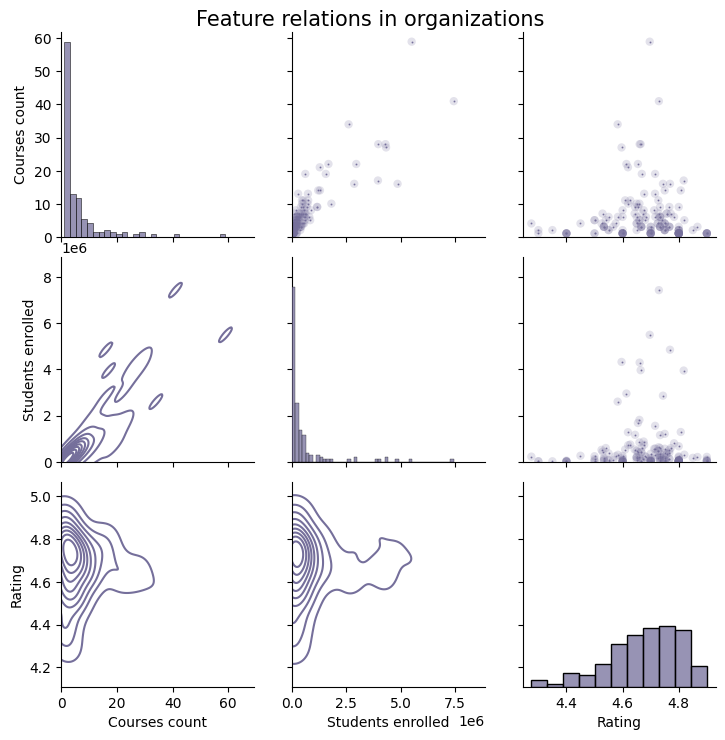

In [38]:
g = sns.PairGrid(courses_data)
g.fig.subplots_adjust(top=0.95)
g.fig.suptitle('Feature relations in organizations', fontsize=15)
g.map_lower(sns.kdeplot, color="#756F9B")
g.map_diag(sns.histplot, color="#756F9B")
g.map_upper(sns.scatterplot, color='#756F9B', s=2)
g.map_upper(sns.scatterplot, color='#756F9B', alpha=0.2, edgecolor='none')

labels = ["Courses count", "Students enrolled", "Rating"]
for i in range(len(labels)):
    g.axes[2, i].set_xlabel(labels[i])
    g.axes[i, 0].set_ylabel(labels[i])

g.axes[1, 1].set_xlim(0)
g.axes[0, 0].set_xlim(0)
g.axes[0, 0].set_ylim(0)
g.axes[1, 1].set_ylim(0)

Please take a note that lowest posible rating is 1, however there are no courses rated lower than 3.3 on average. To see clearer difference between ratings the range was left as it is, but overall all courses are rated similarly. 

There seems to be linear relation between how many courses does organization has and how many students enrolled. There also seems to be some relations between students enrolled and courses count with rating, but it does not look linear. Monotonic associations between variables are going to be assumed. Monotonicity is "less restrictive" than that of a linear relationship. Therefore, Spearman's correlation was used.

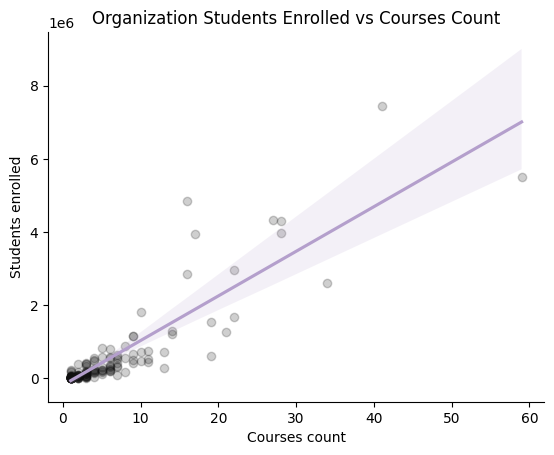

In [39]:
ax = sns.regplot(
    x=courses_data['courses_count'],
    y=courses_data['students_enrolled'],
    scatter_kws={"color": "#0F0F0F", "alpha": 0.2},
    line_kws={"color": "#B49FCC"},
)
ax.set(title='Organization Students Enrolled vs Courses Count', ylabel='Students enrolled', xlabel='Courses count')
sns.despine()

The graph shows trend of organization having more students when they have more courses.

In [40]:
correlation_org = courses_data.corr(method='spearman')
correlation_org

,courses_count,students_enrolled,rating
courses_count,1.000000,0.882473,-0.116711
students_enrolled,0.882473,1.000000,0.007664
rating,-0.116711,0.007664,1.000000


There is strong corelation between courses count and how many students have enrolled. It is as expected, as the more courses the organization has, the more chances the student will enroll into it.

There is also weak negative correlation between rating and how many courses has the organization released, which means that there is a tendency to have lower average rating for courses, when you have a lot of them. Students either have higher expectations for these courses, or quantity does not mean quality. 

Students enrolled with rating correlates extremelly weakly. However, from the graphs we can see that there is some tendencies for organizations with a lot of students and courses to get ratings around 4.7. Ratings for organizations with less courses and students are much more varied.

All of the courses are still well recieved overall as the ratings are high.

### Exploring courses data

In [41]:
most_popular_course = data.loc[data.course_students_enrolled.idxmax()]
most_popular_course

course_title                   Machine Learning
course_organization         Stanford University
course_certificate_type                  COURSE
course_rating                               4.9
course_difficulty                         Mixed
course_students_enrolled                3200000
Name: 6, dtype: object

In [42]:
least_popular_course = data.loc[data.course_students_enrolled.idxmin()]
least_popular_course

course_title                El Abogado del Futuro: Legaltech y la Transfor...
course_organization                                       Universidad Austral
course_certificate_type                                                COURSE
course_rating                                                             5.0
course_difficulty                                                    Beginner
course_students_enrolled                                                 1500
Name: 789, dtype: object

In [43]:
least_popular_course[0]  # full name of the lowest attended course

'El Abogado del Futuro: Legaltech y la Transformación Digital del Derecho'

In [44]:
highest_rated_course = data.loc[data.course_rating.idxmax()]
highest_rated_course

course_title                El Abogado del Futuro: Legaltech y la Transfor...
course_organization                                       Universidad Austral
course_certificate_type                                                COURSE
course_rating                                                             5.0
course_difficulty                                                    Beginner
course_students_enrolled                                                 1500
Name: 789, dtype: object

In [45]:
highest_rated_course[0]  # full name of the highest rated course

'El Abogado del Futuro: Legaltech y la Transformación Digital del Derecho'

In [46]:
lowest_rated_course = data.loc[data.course_rating.idxmin()]
lowest_rated_course

course_title                How To Create a Website in a Weekend! (Project...
course_organization                          The State University of New York
course_certificate_type                                                COURSE
course_rating                                                             3.3
course_difficulty                                                       Mixed
course_students_enrolled                                               140000
Name: 767, dtype: object

In [47]:
lowest_rated_course[0]  # full name of the lowest rated course

'How To Create a Website in a Weekend! (Project-Centered Course)'

The most popular course is Machine Learning by Stanford University (3,200,000 students). The most popular course is attended more than 10 times than on average (average per course students 90,552±6095). We can see that the most popular course is not from most popular organization but it is rated higher than average course (course rating 4.9, when average course ratings are about 4.67±0.005). 

Highest rated course and least attended one is El Abogado del Futuro: Legaltech y la Transformación Digital del Derecho, comes from Universidad Austral in Argentina. Course name translated from Spanish is The Lawyer of the Future: Legaltech and the Digital Transformation of Law. It has low amount of students enrolled in it (1,500). The courses name seems to be very specific, it deals with law and tech, therefore it is not surprising that there is low amount of students enrolled in it. 

Lowest rated course has just 3.3 rating (compared to 4.67±0.005 average ratings). However, even 140,000 students enrolled in it. That's more students than average (90,552±6095). Perhaps students were not able to get what they are promised from the course, were not pleased with the result or there also could be some reason why the course is highly attended and low rated.

In [48]:
correlation = data[['course_rating', 'course_students_enrolled']].corr(method='spearman')
correlation

,course_rating,course_students_enrolled
course_rating,1.000000,0.026831
course_students_enrolled,0.026831,1.000000


Correlation shows very weak positive relation between course rating and students enrolled.

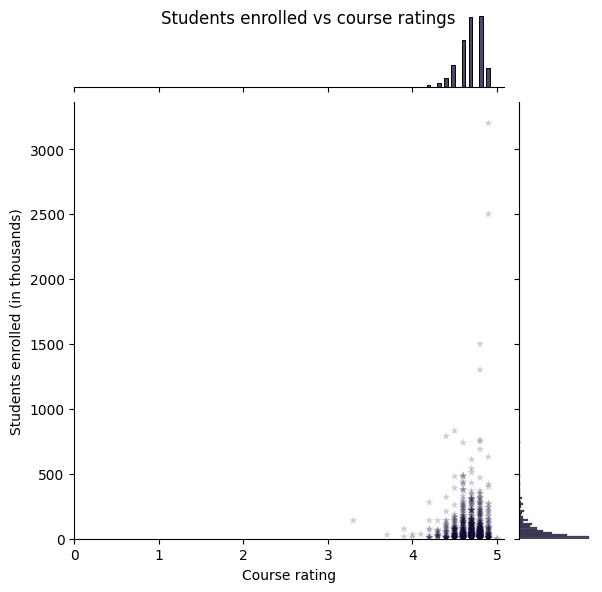

In [49]:
ax = sns.jointplot(
    data=data, x="course_rating", y="course_students_enrolled", alpha=0.2, marker='*', edgecolor='none', color='#100B32'
)
ax.fig.suptitle('Students enrolled vs course ratings')
ax.ax_marg_x.set_xlim(0)
ax.ax_marg_y.set_ylim(0)
ax.ax_joint.set_xlabel('Course rating')
ax.ax_joint.set_ylabel('Students enrolled (in thousands)')
ticks = ax.ax_marg_y.get_yticks()
ax.ax_marg_y.yaxis.set_major_locator(plt.ticker.FixedLocator(ticks))
ax.ax_marg_y.set_yticklabels([int(tick / 1000) for tick in ticks]);

To sum up, looking at just most attendend and lowest rated courses, the relation looked negative. However, correlation is positive. Overall, it looks like there is no relation between course ratings and course students enrolled or relation is minimal. There is also a lot of courses with not that many students and very low count of courses with high amount of students enrolled (exponentially decreasing tendensies for amount of courses with high student enrollement). Most of course ratings seem to be distributed between 4 and 5.

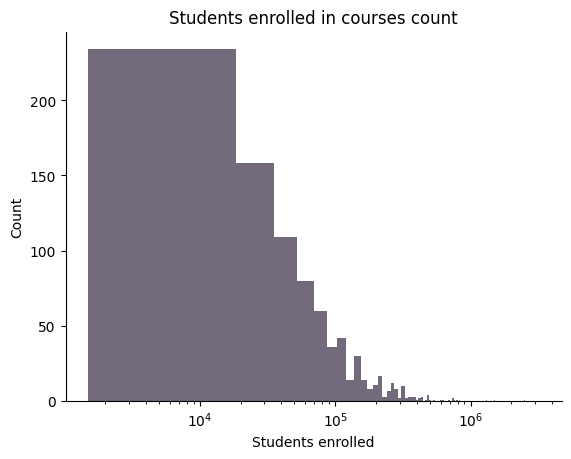

In [50]:
ax = sns.histplot(data=data, x="course_students_enrolled", edgecolor='none', color='#443850')
ax.set(title='Students enrolled in courses count')
sns.despine()
plt.pyplot.xscale('log')
ax.set_xlabel('Students enrolled');

Here we can see that there are some linear tendensies for students enrolled vs number of courses if the scale is logaritmic. It indicates that there are only few courses which are very popular and enrolled students amount decreases exponentially for less popular courses compared to most popular ones.

In [51]:
course_certificate_type_counts = data.course_certificate_type.value_counts()
course_certificate_type_counts

course_certificate_type
COURSE                      582
SPECIALIZATION              297
PROFESSIONAL CERTIFICATE     12
Name: count, dtype: int64

In [52]:
course_difficulty_counts = data.course_difficulty.value_counts()
course_difficulty_counts

course_difficulty
Beginner        487
Intermediate    198
Mixed           187
Advanced         19
Name: count, dtype: int64

In [53]:
certificate_types = ['Course', 'Specialization', 'Profesional certificate']
course_difficulties = ['Beginner', 'Intermediate', 'Mixed', 'Advanced']
plot_names = ['Course Certificate Type', 'Course Difficulty']

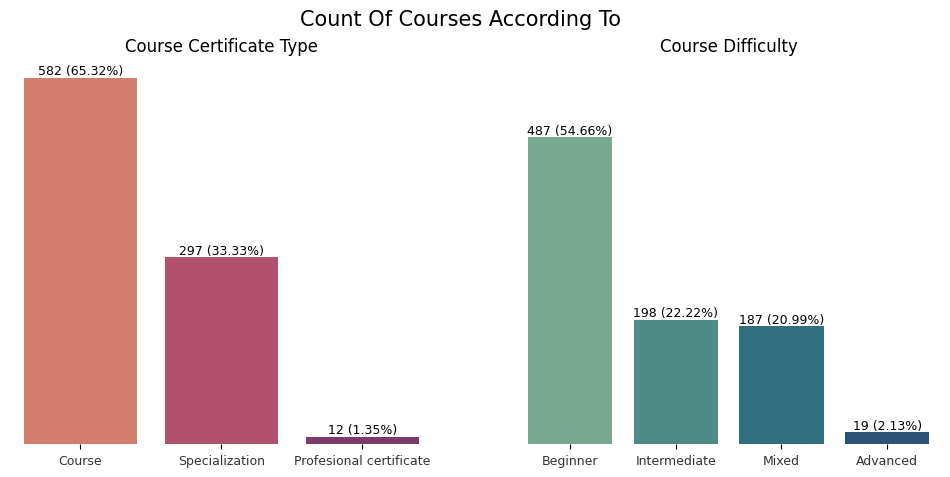

In [54]:
fig, axs = plt.pyplot.subplots(1, 2, sharey=True, figsize=(12, 5))
fig.suptitle('Count Of Courses According To', fontsize=15)
sns.despine(left=True, bottom=True)


def bar_graph_f(data, name, x_names, palet, subplot):
    ax = sns.barplot(x=data.index, y=data, palette=palet, ax=axs[subplot])
    ax.set_title(name)
    ax.set_xticklabels(x_names, fontsize=9, alpha=0.8)
    labels_list = []
    for i in range(len(data)):
        labels_list.append(f'{data[i]} ({count_percentage(data[i], courses_count)}%)')
    ax.bar_label(ax.containers[0], labels=labels_list, fontsize=9)
    ax.tick_params(left=False)
    ax.set(ylabel=None, xlabel=None, yticklabels=[])


ax1 = bar_graph_f(course_certificate_type_counts, plot_names[0], certificate_types, 'flare', 0)
ax2 = bar_graph_f(course_difficulty_counts, plot_names[1], course_difficulties, 'crest', 1)

Most of the courses certification type is course, around third is specialization typer and small percent grants profesional certificate. 

More than half of courses are beginner difficulty courses (54.66%). Intermediate and mixed difficulty courses are around 21% and there is only 2% of advanced difficulty courses.

In [55]:
certificate_course = data[['course_rating', 'course_students_enrolled']][data.course_certificate_type == 'COURSE']
certificate_specialization = data[['course_rating', 'course_students_enrolled']][
    data.course_certificate_type == 'SPECIALIZATION'
]
certificate_professional = data[['course_rating', 'course_students_enrolled']][
    data.course_certificate_type == 'PROFESSIONAL CERTIFICATE'
]

cerficate_type_df_list = [certificate_course, certificate_specialization, certificate_professional]

In [56]:
beginner = data[['course_rating', 'course_students_enrolled']][data.course_difficulty == 'Beginner']
intermediate = data[['course_rating', 'course_students_enrolled']][data.course_difficulty == 'Intermediate']
mixed = data[['course_rating', 'course_students_enrolled']][data.course_difficulty == 'Mixed']
advanced = data[['course_rating', 'course_students_enrolled']][data.course_difficulty == 'Advanced']

difficulty_df_list = [beginner, intermediate, mixed, advanced]

In [57]:
def printing_means_func(df_list, group_names):
    '''
    Function for printing means in list of dataframes
    '''
    for i in range(len(df_list)):
        print(f'{group_names[i]}: rating – {round(df_list[i].mean()[0], 2)}', end='')
        print(f'\u00B1{round(df_list[i].sem()[0], 2)}, students – ', end='')
        print(f'{int(df_list[i].mean()[1])}\u00B1{int(df_list[i].sem()[1])}.')

In [58]:
print('Mean values of course ratings and students enrolled according to course cerfitication type')
printing_means_func(cerficate_type_df_list, certificate_types)

Mean values of course ratings and students enrolled according to course cerfitication type
Course: rating – 4.71±0.01, students – 87854±8100.
Specialization: rating – 4.62±0.01, students – 91791±8846.
Profesional certificate: rating – 4.7±0.03, students – 190700±44812.


In [59]:
data[data.course_certificate_type == 'PROFESSIONAL CERTIFICATE']

,course_title,course_organization,course_certificate_type,course_rating,course_difficulty,course_students_enrolled
56,Arizona State University TESOL,Arizona State University,PROFESSIONAL CERTIFICATE,4.9,Beginner,150000
9,Cloud Engineering with Google Cloud,Google Cloud,PROFESSIONAL CERTIFICATE,4.7,Intermediate,310000
22,Data Engineering with Google Cloud,Google Cloud,PROFESSIONAL CERTIFICATE,4.6,Intermediate,120000
25,Google IT Automation with Python,Google,PROFESSIONAL CERTIFICATE,4.7,Beginner,93000
4,Google IT Support,Google,PROFESSIONAL CERTIFICATE,4.8,Beginner,350000
34,IBM AI Engineering,IBM,PROFESSIONAL CERTIFICATE,4.6,Intermediate,140000
12,IBM Applied AI,IBM,PROFESSIONAL CERTIFICATE,4.6,Beginner,220000
0,IBM Data Science,IBM,PROFESSIONAL CERTIFICATE,4.6,Beginner,480000
160,SAS Programmer,SAS,PROFESSIONAL CERTIFICATE,4.8,Beginner,370000
393,SAS Visual Business Analytics,SAS,PROFESSIONAL CERTIFICATE,4.6,Beginner,2600


In [60]:
print('Mean values of course ratings and students enrolled according to course difficulty')
printing_means_func(difficulty_df_list, course_difficulties)

Mean values of course ratings and students enrolled according to course difficulty
Beginner: rating – 4.68±0.01, students – 81974±5767.
Intermediate: rating – 4.65±0.01, students – 73264±7405.
Mixed: rating – 4.71±0.01, students – 133633±23294.
Advanced: rating – 4.6±0.04, students – 66547±18872.


Looking at the means according to each group, there seems to be more students enrolled on average in profesional certification course types. This might be due to coursera not having a lot of this type of courses. There are a lot more of specialization and course certificate type courses and the student has higher ability to chose one of courses if they are similar, whereas only 1.35% of courses are profesional certificate type and the student might not have luxury of chosing. Profesional certificate courses might also be popular due to their specifics –  they seem to be prepared by big companies (like Google or IBM) and might be required to be accepted into the job or be done while in job. Specialization courses have slightly lower ratings than the rest.

Most of students on average tend to chose mixed rating courses. There is tendency for average amount of students to decrease in comparison with difficulty. Ratings also slightly decrease. Mixed difficulty courses have slightly higher rating than the rest.

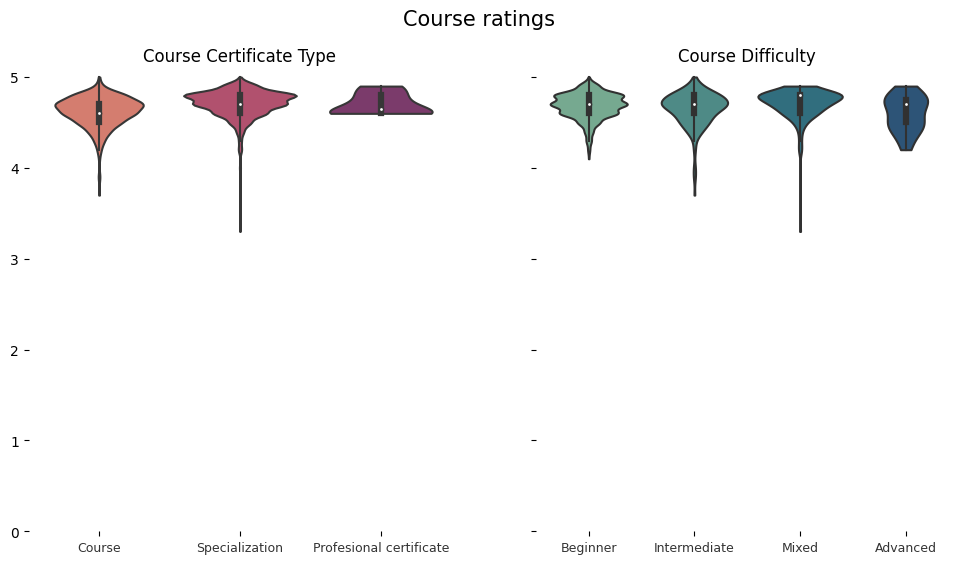

In [61]:
f, axs = plt.pyplot.subplots(1, 2, sharey=True, figsize=(12, 6))
f.suptitle('Course ratings', fontsize=15)
sns.despine(left=True, bottom=True)


def violinplot_f(x, y, name, x_names, palet, subplot, data=data):
    ax = sns.violinplot(data=data, x=x, y=y, palette=palet, ax=axs[subplot], cut=0)
    ax.set_title(name)
    ax.set_xticklabels(x_names, fontsize=9, alpha=0.8)
    labels_list = []
    ax.set(ylabel=None, xlabel=None)
    ax.set_ybound(0)


ax1 = violinplot_f("course_certificate_type", "course_rating", plot_names[0], certificate_types, 'flare', 0)
ax2 = violinplot_f("course_difficulty", "course_rating", plot_names[1], course_difficulties, 'crest', 1)

In groups by course certificate type median course ratings are highest in specialization courses, but they have lowest rated courses too. Profesional certificate courses are least spread out.

Mixed course difficulty courses have highest median and also lowest ratings out of all difficulties. Beginner and intermediate difficulty courses have highest rated courses. Beginner, intemediate and advanced courses have similar ratings.

Overall, course ratings in groups are similar and differences between groups are minimal.

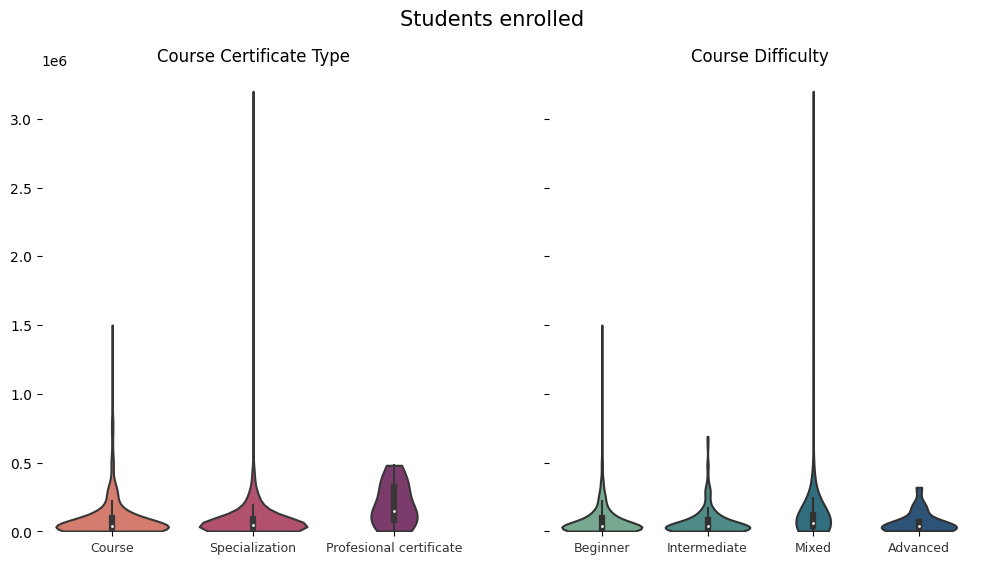

In [62]:
f, axs = plt.pyplot.subplots(1, 2, sharey=True, figsize=(12, 6))
f.suptitle('Students enrolled', fontsize=15)
sns.despine(left=True, bottom=True)

ax1 = violinplot_f("course_certificate_type", "course_students_enrolled", plot_names[0], certificate_types, 'flare', 0)
ax2 = violinplot_f("course_difficulty", "course_students_enrolled", plot_names[1], course_difficulties, 'crest', 1);

Courses with course and specialization course certificate type has some very popular courses attended by a lot of students, but majority of courses are not as popular, and student enrollement count decreases exponentially. The most popular course comes from specialization course certificate type. On other hand profesional certificate course attendance is distributed quite evenly.

There are some amount of beginner, intermediate and mixed courses which are very popular. In advanced difficulty courses are not as popular as the rest. Perhaps, there are less experts in the field to seek courses, or they generally tend not to enroll in courses. Mixed difficulty courses have slightly higher median than the rest, making them most popular on average, the most popular course also comes from this group.

### Python courses statistics compared to rest of courses and widget

In [63]:
# To make search easier later on
courses_lower_case = data.course_title.str.lower()

In [64]:
def search_for_key(key, data=courses_lower_case):
    '''
    Searches for a given key in data.
    By default searches for a key in courses name.
    Returns a boolean mask.
    '''
    return data.str.contains(key.lower())

In [65]:
python_courses = data.loc[search_for_key('Python')]
python_courses.head()

,course_title,course_organization,course_certificate_type,course_rating,course_difficulty,course_students_enrolled
26,Applied Data Science with Python,University of Michigan,SPECIALIZATION,4.5,Intermediate,480000
630,Applied Machine Learning in Python,University of Michigan,COURSE,4.6,Intermediate,150000
491,"Applied Plotting, Charting & Data Representati...",University of Michigan,COURSE,4.6,Intermediate,97000
888,Aprende a programar con Python,Universidad Austral,SPECIALIZATION,4.2,Beginner,6600
536,"Capstone: Retrieving, Processing, and Visualiz...",University of Michigan,COURSE,4.6,Mixed,82000


In [66]:
number_of_python_courses = python_courses.shape[0]
number_of_python_courses

34

In [67]:
python_courses.describe()

,course_rating,course_students_enrolled
count,34.000000,3.400000e+01
mean,4.664706,1.893118e+05
std,0.151522,3.302625e+05
min,4.200000,6.600000e+03
25%,4.600000,3.575000e+04
50%,4.700000,8.250000e+04
75%,4.800000,1.425000e+05
max,4.900000,1.500000e+06


In [68]:
# standart errors for course ratings and course students enrolled means.
python_courses[['course_rating', 'course_students_enrolled']].sem()

course_rating                   0.025986
course_students_enrolled    56639.550936
dtype: float64

We can see that python courses have similar ratings as all the courses (courses with Python – 4.66±0.03, all courses 4.67±0.005 average ratings). Average student enrollment into python course is 189,312±56640, which is more than average (90,552±6095). Therefore, Python courses are more popular than a random course from the dataset.

In [69]:
# List of keys to select for our interactive graph
list_of_keys = ['Python', 'Data', 'Law', 'Machine Learning', 'Excel', 'Website', 'Cooking', 'Gardening']

In [70]:
# Interactive graph


@widgets.interact(key=list_of_keys)
def box_plot_f(key):
    searched_data = data.loc[search_for_key(key)]
    if len(searched_data) == 0:
        return 'Searched keyword is not in the courses names dataset'

    fig, axs = plt.pyplot.subplots(2, figsize=(5, 10))
    fig.suptitle(f'Searched {key} courses, comparison with all')
    sns.despine()

    bplot1 = axs[0].boxplot(
        [searched_data.course_rating, data.course_rating],
        flierprops=dict(marker="x"),
        patch_artist=True,
        showmeans=True,
        meanline=True,
        labels=[key, 'All courses'],
    )
    axs[0].set_title('Course Rating')
    bplot2 = axs[1].boxplot(
        [searched_data.course_students_enrolled, data.course_students_enrolled],
        flierprops=dict(marker="x"),
        patch_artist=True,
        showmeans=True,
        meanline=True,
        labels=[key, 'All courses'],
    )
    axs[1].set_title('Course Students Enrolled')

    colors = ['#DAD4EF', '#100B32']
    for bplot in (bplot1, bplot2):
        for patch, color in zip(bplot['boxes'], colors):
            patch.set_facecolor(color)

    for i in range(len(axs)):
        axs[i].set_ylim(0)
        axs[i].yaxis.grid(True, linestyle=':')

interactive(children=(Dropdown(description='key', options=('Python', 'Data', 'Law', 'Machine Learning', 'Excel…

Here is interactive charts with possibility to search for given keys. The keys are written in list of keys. Green line stands for mean value, and orange one stands for median.

## Summary

* The more courses organization has, the more students they have.
* Course ratings and student enrollement count does not seem to be related.
* Less students the course has the more varied it's rating is.
* There is tendency for average amount of students to decrease in comparison with course difficulty.
* Python courses are more popular than random courses from the dataset

## Findings

There are 891 courses in the Coursera course dataset. It has 6 different features, of which 4 are categorical and 2 are numerical. Categorical features: course title, course organization, course certificate type and course difficulty. Numerical features: course rating and course students enrolled. There are in total 154 different organizations which prepared the courses for Coursera. 

**Organizations in the dataset stats**

Majority of the orgnizations have more than one course (105 out of 154, or 68.18%).

We can see that top 2 most attended organizations are same as ones with most courses, just switched in places: University of Pennsylvania (5,501,300 or 6.82% of all students) and University of Michigan (7,437,700, 9.22%%). There were 7 organizations in top 10 most courses, which are also in top 10 most popular courses. Obviously, having more courses makes your organization more popular to students, but it is not always the case. More than half of students (53%) are in top 10 most popular course organizations. Neither most popular or with most courses organizations are in top highest or lowest rated overall.

There is strong corelation between courses count and how many students have enrolled. It is as expected, as the more courses the organization has, the more chances the student will chose it. There is also weak negative correlation between rating and how many courses has the organization released, which means that there is a tendency to have lower average rating for courses, when you have a lot of them. Students either have higher expectations for these courses, or quantity does not mean quality. From the graphs we saw see that there is some tendencies for organizations with a lot of students and courses to get ratings around 4.7. Ratings for organizations with less courses and students are much more varied.

**Courses stats**

TThe most popular course is Machine Learning by Stanford University (3,200,000 students). The most popular course is attended more than 10 times than on average (average per course students 90,552±6095). We can see that the most popular course is not from most popular organization but it is rated higher than average course (course rating 4.9, when average course ratings are about 4.67±0.005).

Highest rated course and least attended one is El Abogado del Futuro: Legaltech y la Transformación Digital del Derecho, comes from Universidad Austral in Argentina. Course name translated from Spanish is The Lawyer of the Future: Legaltech and the Digital Transformation of Law. It has low amount of students enrolled in it (1,500). The courses name seems to be very specific, it deals with law and tech, therefore it is not surprising that there is low amount of students enrolled in it.

Lowest rated course has just 3.3 rating (compared to 4.67±0.005 average ratings). However, even 140,000 students enrolled in it. That's more students than average (90,552±6095). Perhaps students were not able to get what they are promised from the course, were not pleased with the result or there also could be some reason why the course is highly attended and low rated.

Overall, it looks like there is no relation between course ratings and course students enrolled or relation is minimal. There is also a lot of courses with not that many students and very low count of courses with high amount of students enrolled (exponentially decreasing tendensies for amount of courses with high student enrollement). Most of course ratings seem to be distributed between 4 and 5. There seems to be tendensy to have high course ratings on Coursera. But having high attendance does not guarantee relativelly high course ratings.

**Grouping courses into groups stats**

The courses have 3 certificate types: course specialization and profecional certificate. Most of the courses certification type is course, around third is specialization typer and small percent grants profesional certificate.
Looking at the means according to each group, there seems to be more students enrolled on average in profesional certification course types. This might be due to coursera not having a lot of this type of courses. There are a lot more of specialization and course certificate type courses and the student has higher ability to chose one of courses if they are similar, whereas only 1.35% of courses are profesional ceritificate type and the student might not have luxury of chosing. Profesional certificate courses might also be popular due to their specifics – they seem to be prepared by big companies (like Google or IBM) and might be required to be accepted into the job or be done while in job.  Specialization courses have slightly lower ratings than the rest.

There are also 4 different course difficulty levels: beginner, intermediate, mixed and advanced. More than half of courses are beginner difficulty courses (54.66%). Intermediate and mixed difficulty courses are around 21% and there is only 2% of advanced difficulty courses.
Most of students on average tend to chose mixed rating courses. There is tendency for average amount of students to decrease in comparison with difficulty. Ratings also slightly decrease. Mixed difficulty courses have slightly higher rating than the rest.
Mixed course difficulty courses have highest median and also lowest ratings out of all difficulties. Beginner and intermediate difficulty courses have highest rated courses. Beginner, intemediate and advanced courses have similar ratings.

We can see that python courses have similar ratings as all the courses (courses with Python – 4.66±0.03, all courses 4.67±0.005 average ratings). Average student enrollment into python course is 189,312±56640, which is more than average (90,552±6095). Therefore, Python courses are more popular than a random course from the dataset.

## Suggestions for improvement

No information about how long courses are there. Perhaps low student enrollement in courses is related to the course being new, not because the course or topic is unpopular. To see relation of how frequently courses are updated and their ratings change overtime. Percentage of students finishing the course would be interesting to see. Also, how long on average did they take to finish the course. 

Separating courses into different sectors. Perhaps it could be done by smartly interpreting the course names.

There are courses in other languages than english. Checking statistics based on course language.

Running some statistics between groups, do they belong to same dataset or not. Is there a significant difference between them. Also grouping courses into groups according to both difficulty and course certificate type.

Improving interactive graph. Being able to type in your own keyword instead of chosing one provided in the key list. Being able to compare two groups, not just one group to the main dataset. Also including ability to chose between different difficulty levels and certification types.